# 2.2. GIẢI THUẬT 2: SUPPORT VECTOR MACHINE (SVM)

# 2.2.2 BÀI TOÁN 1  – Phân loại hoa Iris bằng SVM
## Nhiệm vụ 1 – Xây dựng mô hình SVM để phân loại các loài hoa cẩm chướng
### Bước 1 – Nạp dữ liệu, xem thông tin các feature, chia train/test (80:20)

In [1]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
# Download&Load dữ liệu iris từ datasets của scikit-learn
iris = datasets.load_iris()
# Hiển thị mô ta dữ liệu, chỉ có trong các bộ dữ liệu chuẩn và mở để học tập và nghiên cứu
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [2]:
# Từ tập dữ liệu ban đầu, tách lấy ma trận biểu diễn các đặc trưng và nhãn.
data = iris.data
target = iris.target
# TODO: Chia dữ liệu và nhãn thành 2 tập dữ liệu huấn luyện và dữ liệu kiểm tra theo tỉ lệ 80:20
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size = 0.2, random_state=101)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Tên đặc trưng:', iris.feature_names)
print('Tên lớp      :', list(iris.target_names))

Train: (120, 4) | Test: (30, 4)
Tên đặc trưng: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên lớp      : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### Bước 2 – Tạo mô hình SVM với dữ liệu đã chuẩn bị

In [3]:
from sklearn import svm
# khởi tạo mô hình phân lớp
clf = svm.SVC()
# Sử dụng phương thức 'fit' để huấn luyện mô hình với dữ liệu huấn luyện và nhãn huấn luyện
# fit (X,Y) với X là tập các đối tượng, Y là tập nhãn tương ứng của đối tượng.
clf.fit(X_train, y_train)

SVC()

### Bước 3 – Đánh giá độ chính xác

In [4]:
# Tính độ chính xác trên tập huấn luyện và tập kiểm tra
train_acc = clf.score(X_train,y_train)
val_acc = clf.score(X_test,y_test)
print('Training accuracy: {}'.format(train_acc))
print('Validation accuracy: {}'.format(val_acc))

Training accuracy: 0.95
Validation accuracy: 0.9666666666666667


### Bước 4 – Tìm tham số kernel tối ưu cho mô hình SVM
Thử lần lượt 4 kernel: linear, poly, rbf, sigmoid và giữ kernel cho độ chính xác cao nhất.

In [ ]:
# best_svm, best_val_acc và best_kernel lần lượt là các biến lưu mô hình tốt nhất,
# độ chính xác cao nhất trên tập kiểm tra và kernel tốt nhất
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
best_svm = None
best_val_acc = -1
best_kernel = None
# Huấn luyện các mô hình dựa trên dữ liệu huấn luyện và tham số kernel
# Tính toán độ chính xác trên tập huấn luyện và tập kiểm tra để tìm được mô hình tốt nhất
for i in range(4):
    clf = svm.SVC(kernel=kernels[i], probability=True)
    clf.fit(X_train, y_train)
    tmp_val_acc = clf.score(X_test, y_test)
    print('kernel = %-8s | train acc = %.4f | test acc = %.4f' % (kernels[i], clf.score(X_train, y_train), tmp_val_acc))
    if (tmp_val_acc > best_val_acc):
        best_val_acc = tmp_val_acc
        best_svm = clf
        best_kernel = kernels[i]
# Hiển thị mô hình tốt nhất cùng với độ chính xác
print("Best validation accuracy : {} with kernel: {}".format(best_val_acc, best_kernel))
# Mô hình tốt nhất nên có độ chính xác xấp xỉ 86,67%

kernel = linear   | train acc = 0.9833 | test acc = 1.0000
kernel = poly     | train acc = 0.9833 | test acc = 1.0000
kernel = rbf      | train acc = 0.9500 | test acc = 0.9667
kernel = sigmoid  | train acc = 0.3500 | test acc = 0.2667
Best validation accuracy : 1.0 with kernel: linear


### Mở rộng – Dùng GridSearchCV để tìm tham số tối ưu cho mô hình SVM
Tìm đồng thời kernel, C, gamma bằng kiểm định chéo 5 lần chỉ trên tập train, sau đó mới đánh giá một lần trên tập test. Dữ liệu được chuẩn hóa bằng StandardScaler trong Pipeline (SVM rất nhạy với thang đo của đặc trưng).

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([('scaler', StandardScaler()), ('svc', svm.SVC())])
param_grid = {'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
              'svc__C': [0.1, 1, 10, 100],
              'svc__gamma': ['scale', 0.01, 0.1, 1]}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print('Tham số tốt nhất      :', grid.best_params_)
print('Accuracy CV (train)   : %.4f' % grid.best_score_)
print('Accuracy trên tập test: %.4f' % grid.score(X_test, y_test))

Tham số tốt nhất      : {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Accuracy CV (train)   : 0.9667
Accuracy trên tập test: 1.0000


# 2.2.2. BÀI TOÁN 2 – Nhận diện chữ số viết tay (Handwritten Digits) bằng SVM
## Nhiệm vụ 1 – Tìm hiểu về cách biểu diễn và hiển thị các ảnh từ tập dữ liệu là hình ảnh
### Bước 1 – Import thư viện và tải dữ liệu là tập các hình ảnh viết tay từ số 0 đến số 9
Mỗi ảnh có kích thước 8×8 = 64 điểm ảnh (mức xám 0–16); tổng cộng 1797 ảnh.

In [7]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
digits = load_digits(n_class=10)

### Bước 2 – Khảo sát thông tin có trong digits

In [8]:
#thông tin toàn bộ dữ liệu đã tải về
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)), 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)), 'frame': None, 'feature_names': ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_

In [9]:
#xem thông tin của một hình dưới dạng ma trận 8 x 8
digits['data'][0].reshape(8,8)

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [10]:
#xem thông tin của một hình dưới dạng mảng
digits['data'][0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [11]:
#xem thông tin 9 nhãn đầu tiên
digits['target'][0:9]

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

### Bước 3 – Vẽ 64 ảnh đầu tiên từ ma trận 8×8

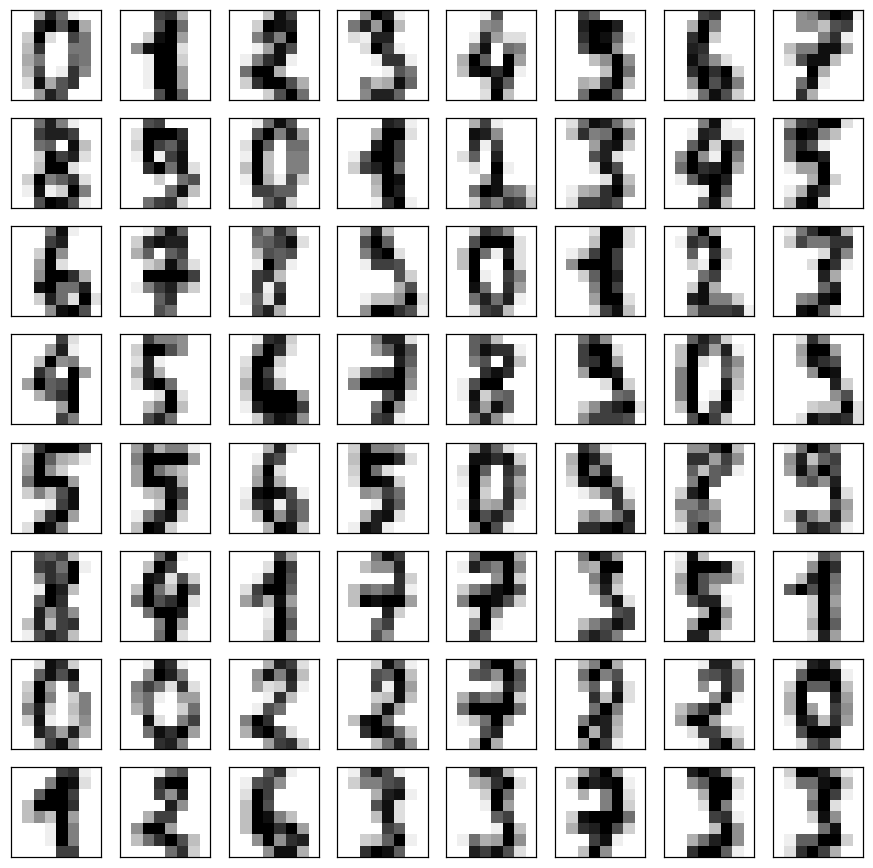

In [12]:
# Each Digit is represented in digits.images as a matrix of 8x8 = 64 pixels. Each of the 64 values represent
# a greyscale. The Greyscale are then plotted in the right scale by the imshow method.
fig, ax = plt.subplots(8,8, figsize=(10,10))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])

### Bước 4 – Vẽ một ảnh từ ma trận 8 x 8

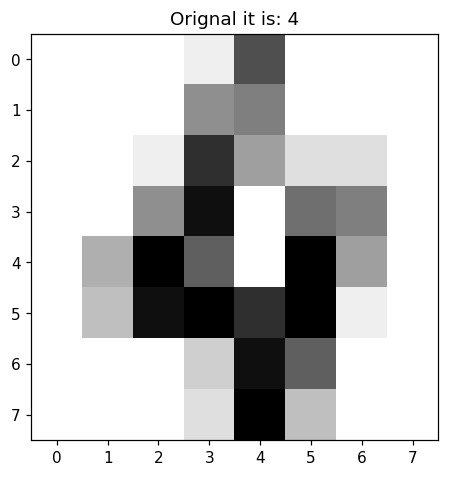

In [13]:
# Hàm vẽ 1 ảnh có kích thước 8 x 8 (ảnh lấy từ ma images)
def view_digit(index):
    plt.imshow(digits.images[index] , cmap = plt.cm.gray_r)
    plt.title('Orignal it is: '+ str(digits.target[index]))
    plt.show()
# vẽ ảnh ở vị trí thứ 4
view_digit(4)

## Nhiệm vụ 2 – Xây dựng mô hình SVM để nhận diện chữ viết tay từ 0 – 9
### Bước 1 – CChuẩn bị dữ liệu và xây dựng mô hình SVM
Huấn luyện trên 1500 ảnh đầu, dự đoán các ảnh từ vị trí 1501 trở đi (296 ảnh).  
- gamma: độ phình của kernel RBF – càng lớn mô hình càng bám sát dữ liệu huấn luyện.  
- C: hệ số phạt lỗi – điều chỉnh sự đánh đổi giữa biên quyết định mượt và phân loại đúng toàn bộ điểm train.

In [14]:
# Thực hiện import các thư viện cần thiết để xây dựng mô hình SVM
from sklearn import svm
main_data = digits['data']
targets = digits['target']
svc = svm.SVC(gamma=0.001 , C = 100)
# GAMMA is a parameter for non linear hyperplanes.
# The higher the gamma value it tries to exactly fit the training data set
# C is the penalty parameter of the error term.
# It controls the trade off between smooth decision boundary and classifying the training points correctly.
svc.fit(main_data[:1500] , targets[:1500])
predictions = svc.predict(main_data[1501:])
# list(zip(predictions , targets[1501:]))
print('Số ảnh test:', len(predictions))
print('Accuracy   : %.4f' % (predictions == targets[1501:]).mean())

Số ảnh test: 296
Accuracy   : 0.9527


### Bước 2 – Đánh giá hiệu quả của mô hình với Confusion Matrix

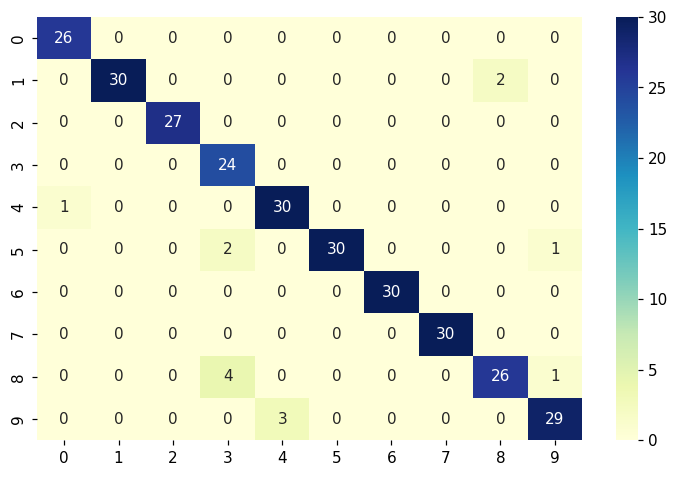

<Axes: >

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(predictions, targets[1501:])
conf_matrix = pd.DataFrame(data = cm)
plt.figure(figsize = (8,5))
sns.heatmap(conf_matrix, annot=True,fmt='d',cmap="YlGnBu");

### Bước 3 – In kết quả dạng văn bản (precision, recall, F1 theo từng lớp)

In [16]:
from sklearn.metrics import classification_report
print(classification_report(predictions, targets[1501:]))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        26
           1       1.00      0.94      0.97        32
           2       1.00      1.00      1.00        27
           3       0.80      1.00      0.89        24
           4       0.91      0.97      0.94        31
           5       1.00      0.91      0.95        33
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.93      0.84      0.88        31
           9       0.94      0.91      0.92        32

    accuracy                           0.95       296
   macro avg       0.95      0.96      0.95       296
weighted avg       0.96      0.95      0.95       296



### Mở rộng – Cùng đánh giá nhưng đúng thứ tự (y_true, y_pred)

              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.94      1.00      0.97        30
           2       1.00      1.00      1.00        27
           3       1.00      0.80      0.89        30
           4       0.97      0.91      0.94        33
           5       0.91      1.00      0.95        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.84      0.93      0.88        28
           9       0.91      0.94      0.92        31

    accuracy                           0.95       296
   macro avg       0.96      0.95      0.95       296
weighted avg       0.96      0.95      0.95       296



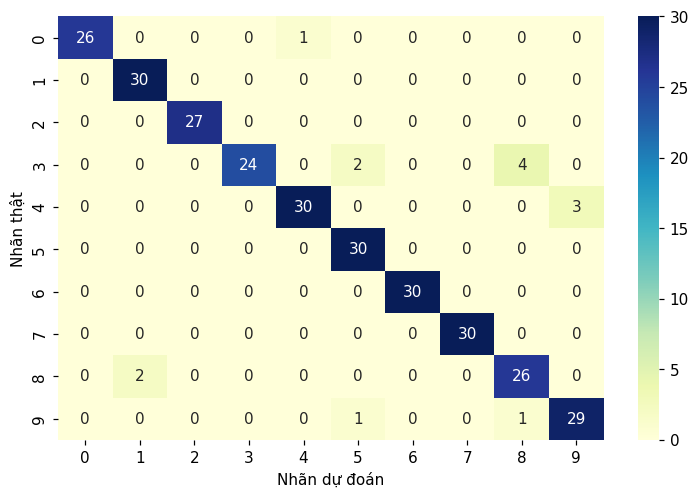

In [17]:
y_true = targets[1501:]
cm2 = confusion_matrix(y_true, predictions)
plt.figure(figsize = (8,5))
sns.heatmap(pd.DataFrame(cm2), annot=True, fmt='d', cmap="YlGnBu")
plt.xlabel('Nhãn dự đoán'); plt.ylabel('Nhãn thật')
print(classification_report(y_true, predictions))

Số ảnh sai: 14 / 296


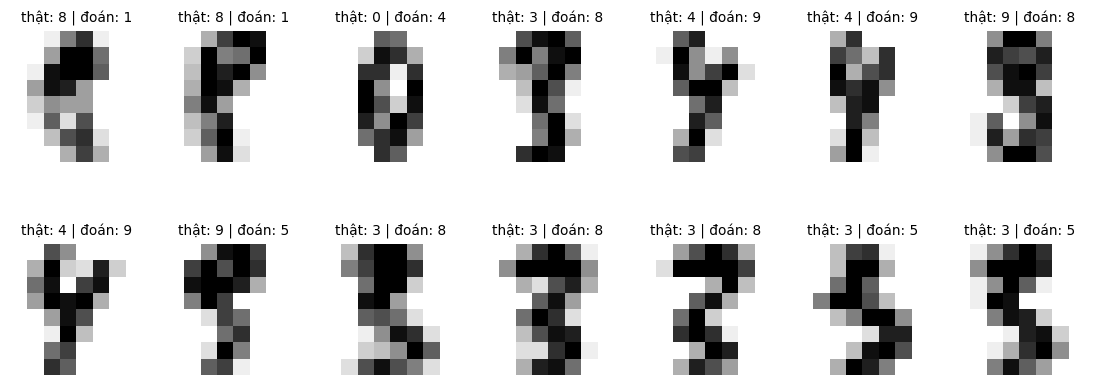

In [18]:
# Những ảnh bị nhận diện sai
wrong = np.where(predictions != y_true)[0]
print('Số ảnh sai:', len(wrong), '/', len(y_true))
if len(wrong):
    ncols = 7; nrows = int(np.ceil(len(wrong) / ncols))
    fig, ax = plt.subplots(nrows, ncols, figsize=(1.8*ncols, 2.3*nrows))
    for a in np.atleast_1d(ax).flat: a.axis('off')
    for a, k in zip(np.atleast_1d(ax).flat, wrong):
        a.imshow(digits.images[1501 + k], cmap='gray_r')
        a.set_title('thật: %d | đoán: %d' % (y_true[k], predictions[k]), fontsize=9)